# Assignment 2: Transfer Learning, Network Surgery, and Fine-Tuning

In this assignment, you will use convolutional networks to study a progression from random parameters, to pre-trained parameters (previously optimized on other data), to fine-tuned parameters (now optimized on the current data). To illustrate local modeling and the use of convolution we will go from image classification to pixel classification ("semantic segmentation").

You will:

1. build a reproducible data pipeline for image classification for our custom mini-ImageNet dataset,
2. verify pretrained models on the popular ImageNet dataset before modifying them,
3. replace and initialize classification output layers (also known as "heads"),
4. compare transfer learning by feature extraction (re-using existing features) with full fine-tuning (optimizing to update the features),
5. extend an image classification model into a pixel classification model by _fully_ convolutional inference and optimization.

### Datasets and Labels

We will work with two custom datasets: mini-ImageNet for image classification and mini-PASCAL for pixel classification. The mini-ImageNet classification dataset contains **10 object classes** aligned with the classes of mini-PASCAL so we can compare global image classification with local pixel classification for the same object classes.

The classes are aeroplane, bird, boat, bottle, bus, car, cat, chair, dog,  and train.

- In **Part 3**, an auxiliary 11th label, **`others`**, is used only when collapsing the original 1000 ImageNet outputs for evaluation. It is **not** a training label in mini-ImageNet.
- In **Parts 4–6**, the trainable classification output layers are **10-way**.
- In **Part 8**, semantic segmentation uses **11 labels: 10 object classes + 1 background class**.

### Computation and Runtime Type

**Remember to set the runtime to GPU (T4) computation!**
This assignment focuses on training and re-training so accelerated computation is a must.

### Advice on Answering

For each text question, please give a **full** answer that addresses each part of the question but a _short_ answer. For each point the expectation is a sentence or few and not a paragraph and certainly not a page.

For each code question, please keep it readable by using clear names and include comments if this helps you follow the code and explain your thinking.

## Dataset provenance

The prepared dataset has:

- **10 coarse classes** derived from ImageNet labels and chosen to align with PASCAL labels
- **3,500 training images**
- **500 validation images**
- short side stored at approximately **224 px**

Importantly:

- local `train/` was sampled from the official ImageNet **train** split,
- local `val/` was sampled from the official ImageNet **validation** split.

They are therefore not re-split from a single common pool.

## 0. Dataset download

In [1]:
DOWNLOAD_DATA = True

GOOGLE_DRIVE_FILE_ID = "11KtOs_7B6bTIIFcEkhw_CQZzFGXr6TDX"

if DOWNLOAD_DATA:
    !uv pip -q install gdown
    # !rm -rf /content/mini_imagenet_pascal10
    # !rm -f /content/mini_imagenet_pascal10.zip
    !gdown "$GOOGLE_DRIVE_FILE_ID" -O content/mini_imagenet_pascal10.zip
    !unzip -q -o content/mini_imagenet_pascal10.zip -d content
    print("Downloaded and extracted.")
else:
    print("Skipping download. Using the existing local dataset.")


Using cookies from /home/jaden/.cache/gdown/cookies.txt
Downloading...
From (original): https://drive.google.com/uc?id=11KtOs_7B6bTIIFcEkhw_CQZzFGXr6TDX
From (redirected): https://drive.google.com/uc?id=11KtOs_7B6bTIIFcEkhw_CQZzFGXr6TDX&confirm=t&uuid=56f09a86-85ed-4770-a964-734e36e96beb
To: /home/jaden/Documents/CPSC-Notes/2026W/AI 360/A2/content/mini_imagenet_pascal10.zip
100%|█████████████████████████████████████| 83.1M/83.1M [00:07<00:00, 11.2MB/s]
Downloaded and extracted.


## 1. Imports, device, and reproducibility

In [2]:
import copy
import random
import time
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import DataLoader
from torchvision import datasets
from torchvision import transforms as T
from torchvision.models import (
    resnet18,
    ResNet18_Weights,
    resnet50,
    ResNet50_Weights,
    vgg16,
    VGG16_Weights,
)
from tqdm import tqdm


SEED = 42
HEAD_SEED = 12345


def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True, warn_only=True)


seed_everything()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
  raise ValueError("This is a CPU runtime. Configure your runtime type for GPU computation!")


! cd "/home/jaden/Documents/CPSC-Notes/2026W/AI 360/A2"

Device: cuda
GPU: NVIDIA GeForce RTX 5070 Ti


# Part 1 — Dataset, preprocessing, and DataLoader

A pretrained model is only one component of a deep-learning system. Input preprocessing and data loading are part of the system too.

## 1.1 Construct the train/validation transforms

**Task:** define suitable augmentation for training and deterministic preprocessing for validation.
Note that we have imported `from torchvision import transforms as T` for you so check the [torchvision.transforms documentation](https://docs.pytorch.org/vision/0.9/transforms.html).

Use the standard ImageNet normalization statistics:

```python
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]
```

In [3]:
DATA_ROOT = Path("content/mini_imagenet_pascal10")
TRAIN_ROOT = DATA_ROOT / "train"
VAL_ROOT = DATA_ROOT / "val"

assert TRAIN_ROOT.exists(), f"Missing: {TRAIN_ROOT}"
assert VAL_ROOT.exists(), f"Missing: {VAL_ROOT}"

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


In [4]:
# TODO: Define `train_transform` and `val_transform`.
# Your code here.
train_transform = T.Compose([
    T.Resize(256),
    T.CenterCrop(224),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

val_transform = T.Compose([
    T.Resize(256),
    T.CenterCrop(224),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])
                  

## 1.2 Build the datasets

**Task:** use `torchvision.datasets.ImageFolder` (see [torchvision.datasets documentation](https://docs.pytorch.org/vision/0.9/datasets.html)) to construct the training and validation datasets. Verify that both splits use the same class-to-index mapping.


In [5]:
# NOTE: v2 edit
# TODO: Construct `train_dataset` and `val_dataset`
# ! ls .
train_dataset = datasets.ImageFolder("./content/mini_imagenet_pascal10/train", transform=train_transform)
val_dataset = datasets.ImageFolder("./content/mini_imagenet_pascal10/val", transform=val_transform)

In [6]:
# NOTE: v2 edit
# verify that both splits use the same class-to-index mapping.
assert train_dataset.class_to_idx == val_dataset.class_to_idx

# collect metadata on our custom dataset
CLASSES = train_dataset.classes
NUM_CLASSES = len(CLASSES)

print("Classes:", CLASSES)
print("Class-to-index mapping:", train_dataset.class_to_idx)
print("Train images:", len(train_dataset))
print("Validation images:", len(val_dataset))

Classes: ['aeroplane', 'bird', 'boat', 'bottle', 'bus', 'car', 'cat', 'chair', 'dog', 'train']
Class-to-index mapping: {'aeroplane': 0, 'bird': 1, 'boat': 2, 'bottle': 3, 'bus': 4, 'car': 5, 'cat': 6, 'chair': 7, 'dog': 8, 'train': 9}
Train images: 3500
Validation images: 500


### Check class balance

Inspect the printed output to ensure there are the same number of images for each class.

In [7]:
train_counts = Counter(train_dataset.targets)
val_counts = Counter(val_dataset.targets)

print("TRAIN")
for class_id, class_name in enumerate(CLASSES):
    print(f"{class_name:12s}: {train_counts[class_id]}")

print("\nVAL")
for class_id, class_name in enumerate(CLASSES):
    print(f"{class_name:12s}: {val_counts[class_id]}")

assert len(set(val_counts.values())) == 1, (
    "Validation classes are not balanced; zero-init loss is still log(K), "
    "but argmax accuracy need not be exactly 1/K."
)

TRAIN
aeroplane   : 350
bird        : 350
boat        : 350
bottle      : 350
bus         : 350
car         : 350
cat         : 350
chair       : 350
dog         : 350
train       : 350

VAL
aeroplane   : 50
bird        : 50
boat        : 50
bottle      : 50
bus         : 50
car         : 50
cat         : 50
chair       : 50
dog         : 50
train       : 50


## 1.3 Build the DataLoaders

**Task:** construct a training `DataLoader` and a validation `DataLoader`. See the [torch.utils.data documentation](https://docs.pytorch.org/docs/2.14/data.html). Decide which split should be shuffled, and keep the comparison reproducible by using the provided random seed as shown.


In [8]:
BATCH_SIZE = 32

def make_loaders(seed=SEED):
    # make loading reproducible
    generator = torch.Generator()
    generator.manual_seed(seed)
    # TODO: Construct and return `(train_loader, val_loader)`.
    # Your code here.
    return DataLoader(train_dataset, BATCH_SIZE, shuffle=True, generator=generator), DataLoader(val_dataset, BATCH_SIZE)

In [9]:
train_loader, val_loader = make_loaders()

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)


Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])


### Short-answer question 1

**Question:** Why do we shuffle the training set but not the validation set?


**Answer**: TODO

### Visualize a training batch

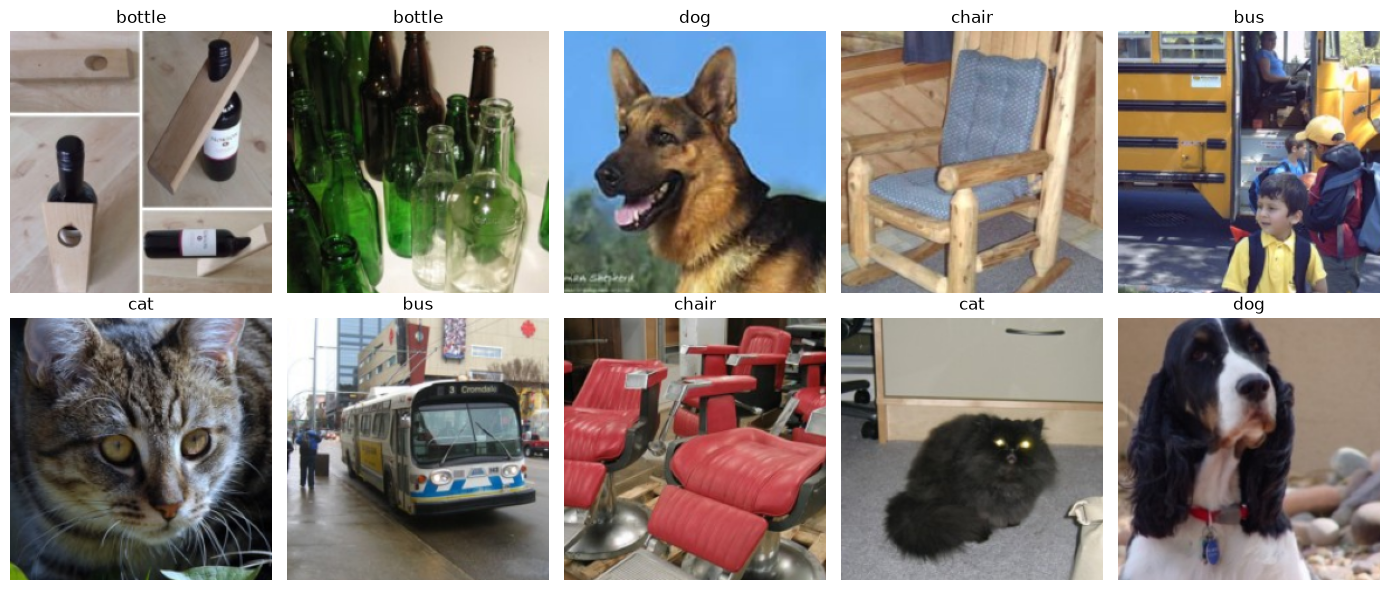

In [10]:
mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std = torch.tensor(IMAGENET_STD).view(3, 1, 1)


def denormalize(image):
    return (image.cpu() * std + mean).clamp(0, 1)


fig, axes = plt.subplots(2, 5, figsize=(14, 6))

for ax, image, label in zip(
    axes.flat,
    images[:10],
    labels[:10],
):
    display_image = (
        denormalize(image)
        .permute(1, 2, 0)
        .numpy()
    )

    ax.imshow(display_image)
    ax.set_title(CLASSES[label.item()])
    ax.axis("off")

plt.tight_layout()
plt.show()

# Part 2 — Inspect the model architectures

**Question:** What are the architectures of the Resnet-18 and VGG-16 models? Identify the output layer used by each network: what type of layer is it and what are its parameter dimensions?

In [11]:
# Load the pretrained ResNet-18 and VGG-16 models
resnet_demo = resnet18(
    weights=ResNet18_Weights.DEFAULT
)

vgg_demo = vgg16(
    weights=VGG16_Weights.DEFAULT
)
# Print them (notice how PyTorch formats the architectures nicely)
print("=" * 80)
print("RESNET-18")
print("=" * 80)
print(resnet_demo)

print("=" * 80)
print("VGG-16")
print("=" * 80)
print(vgg_demo)

RESNET-18
ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_r

In [12]:
# Identify their final classifier layers and their parameter dimensions by printing these layers.
print(resnet_demo.fc)
print(vgg_demo.classifier)

Linear(in_features=512, out_features=1000, bias=True)
Sequential(
  (0): Linear(in_features=25088, out_features=4096, bias=True)
  (1): ReLU(inplace=True)
  (2): Dropout(p=0.5, inplace=False)
  (3): Linear(in_features=4096, out_features=4096, bias=True)
  (4): ReLU(inplace=True)
  (5): Dropout(p=0.5, inplace=False)
  (6): Linear(in_features=4096, out_features=1000, bias=True)
)


In [13]:
# del resnet_demo
# del vgg_demo

# Part 3 — Sanity check with off-the-shelf ImageNet models

Before changing any layer, and the output layer (or "head") in particular, verify that the pretrained models and the data pipeline work together.

The pretrained networks produce **1000 ImageNet logits**, while our dataset uses 10 coarse PASCAL-aligned labels. We map every ImageNet class to one of the 10 coarse categories or to an auxiliary **`others`** category.

This gives an **11-way evaluation space only for this sanity check**. A prediction of `others` on our mini-ImageNet validation set counts as incorrect.


In [14]:
# Canonical ImageNet-1K class indices per PASCAL-aligned superclass.
# The same mapping is reused for coarse-average head initialization later.
PASCAL_TO_IMAGENET_IDS = {
    "aeroplane": [404, 895],                                   # airliner, warplane
    "bird":      list(range(7, 25)) + list(range(80, 101)) + list(range(127, 147)),
    "boat":      [403, 472, 484, 510, 554, 576, 625, 628, 724, 780, 814, 833, 871, 914],
    "bottle":    [440, 720, 737, 898, 907],
    "bus":       [654, 779, 874],                              # minibus, school bus, trolleybus
    "car":       [407, 436, 468, 511, 609, 627, 656, 661, 751, 817],
    "cat":       list(range(281, 286)),                        # domestic cats only
    "chair":     [423, 559, 765, 857],
    "dog":       list(range(151, 269)),
    "train":     [466, 547, 565, 705, 820, 829],
}

assert list(PASCAL_TO_IMAGENET_IDS) == CLASSES

# 10 dataset classes + one catch-all class used only for untouched-model evaluation.
PRETRAINED_SUPERCLASS_NAMES = CLASSES + ["others"]

# 1000 -> 11 lookup; anything not listed maps to "others".
idx_to_super = torch.full(
    (1000,),
    len(PASCAL_TO_IMAGENET_IDS),
    dtype=torch.long,
)
for superclass_id, imagenet_ids in enumerate(PASCAL_TO_IMAGENET_IDS.values()):
    idx_to_super[imagenet_ids] = superclass_id
idx_to_super = idx_to_super.to(device)

pretrained_models = {
    "ResNet-18": resnet18(weights=ResNet18_Weights.IMAGENET1K_V1),
    "VGG-16": vgg16(weights=VGG16_Weights.IMAGENET1K_V1),
}
pretrained_models = {
    name: model.to(device).eval()
    for name, model in pretrained_models.items()
}

# One deterministic validation example per coarse class for visualization.
sanity_indices = [
    val_dataset.targets.index(class_id)
    for class_id in range(NUM_CLASSES)
]
sanity_images = torch.stack([
    val_dataset[index][0]
    for index in sanity_indices
])
sanity_labels = torch.tensor([
    val_dataset[index][1]
    for index in sanity_indices
])


### Shared evaluation helpers

`evaluate_superclass_model` reports loss, top-1 accuracy, and per-class accuracy on the 10 dataset labels. Because the model has 11 outputs in this section, predicting `others` is automatically counted as wrong.


In [15]:
@torch.no_grad()
def evaluate_superclass_model(model, loader):
    model.eval()
    total_loss, total_correct, total = 0.0, 0, 0
    class_correct = torch.zeros(NUM_CLASSES)
    class_total = torch.zeros(NUM_CLASSES)

    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        pred = logits.argmax(1)

        total_loss += F.cross_entropy(logits, y, reduction="sum").item()
        total_correct += (pred == y).sum().item()
        total += y.size(0)
        class_total += torch.bincount(y, minlength=NUM_CLASSES).cpu()
        class_correct += torch.bincount(y[pred == y], minlength=NUM_CLASSES).cpu()

    return {
        "loss": total_loss / total,
        "accuracy": total_correct / total,
        "per_class_accuracy": (class_correct / class_total).tolist(),
    }


def print_superclass_metrics(title, metrics):
    print(title)
    print(f"  Loss:     {metrics['loss']:.4f}")
    print(f"  Accuracy: {metrics['accuracy']:.2%}")
    for name, acc in zip(CLASSES, metrics["per_class_accuracy"]):
        print(f"    {name:12s}: {acc:.2%}")


@torch.no_grad()
def show_superclass_predictions(models, images, labels):
    preds = {}
    for name, m in models.items():
        conf, pred = m(images.to(device)).softmax(-1).max(-1)
        preds[name] = (pred.tolist(), conf.tolist())

    fig, axes = plt.subplots(2, 5, figsize=(16, 8))
    for i, (ax, image, label) in enumerate(zip(axes.flat, images, labels)):
        ax.imshow(denormalize(image).permute(1, 2, 0).numpy())
        lines = [f"true: {CLASSES[label.item()]}"]
        for name, (pred, conf) in preds.items():
            lines.append(f"{name}: {PRETRAINED_SUPERCLASS_NAMES[pred[i]]} ({conf[i]:.2f})")
        ax.set_title("\n".join(lines), fontsize=8)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## 3.1 Collapse 1000 ImageNet probabilities into 11 superclasses

Run the original 1000-way model, then sum the softmax probabilities of all ImageNet classes assigned to each superclass:

$$
p(s \mid x) = \sum_{i \in s} \operatorname{softmax}(Wh+b)_i.
$$

The wrapper returns log-probabilities so it can be evaluated with cross-entropy / negative log-likelihood.


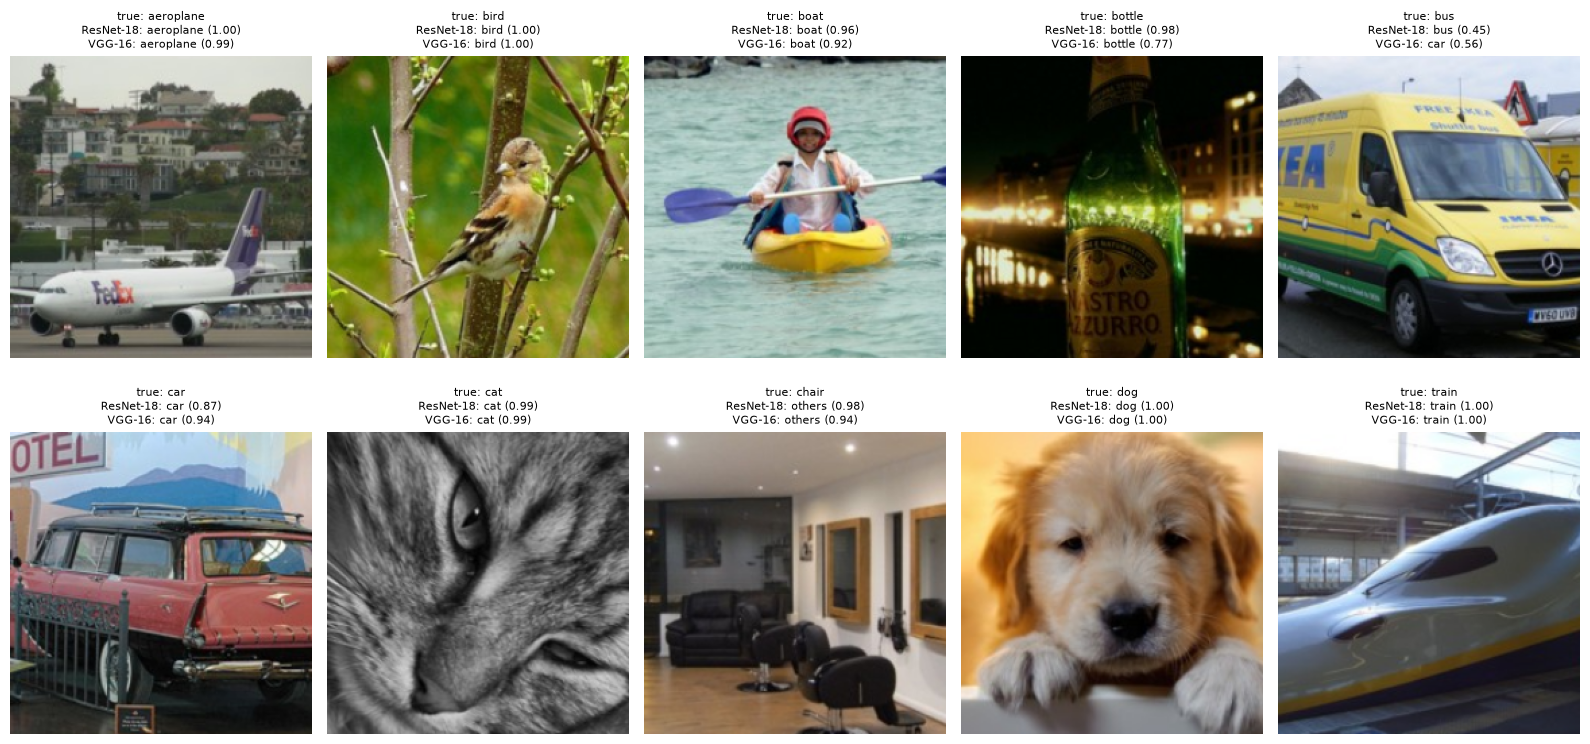

In [16]:
class SuperclassModel(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, x):
        probs = self.model(x).softmax(-1)                                 # (B, 1000)
        super_probs = torch.zeros(x.size(0), len(PRETRAINED_SUPERCLASS_NAMES), device=x.device)
        super_probs.index_add_(1, idx_to_super, probs)                    # (B, 11)
        return super_probs.clamp_min(1e-12).log()

prob_sum_models = {name: SuperclassModel(m).eval() for name, m in pretrained_models.items()}

show_superclass_predictions(prob_sum_models, sanity_images, sanity_labels)

In [17]:
for name, m in prob_sum_models.items():
    print_superclass_metrics(f"{name} (probability sum)", evaluate_superclass_model(m, val_loader))

ResNet-18 (probability sum)
  Loss:     0.5500
  Accuracy: 83.00%
    aeroplane   : 82.00%
    bird        : 100.00%
    boat        : 98.00%
    bottle      : 56.00%
    bus         : 88.00%
    car         : 84.00%
    cat         : 80.00%
    chair       : 56.00%
    dog         : 98.00%
    train       : 88.00%
VGG-16 (probability sum)
  Loss:     0.5092
  Accuracy: 83.20%
    aeroplane   : 88.00%
    bird        : 98.00%
    boat        : 98.00%
    bottle      : 52.00%
    bus         : 86.00%
    car         : 86.00%
    cat         : 80.00%
    chair       : 54.00%
    dog         : 100.00%
    train       : 90.00%


## 3.2 Compress the 1000-way head by averaging weights and biases

As a second no-training baseline, average the weight rows and biases assigned to each superclass. The auxiliary `others` row averages all ImageNet classes not assigned to one of the 10 PASCAL-aligned groups.

This produces an 11-way linear layer and lets us compare **probability aggregation** against **parameter aggregation** before any fine-tuning.


ResNet-18  head: (11, 512)
VGG-16     head: (11, 4096)


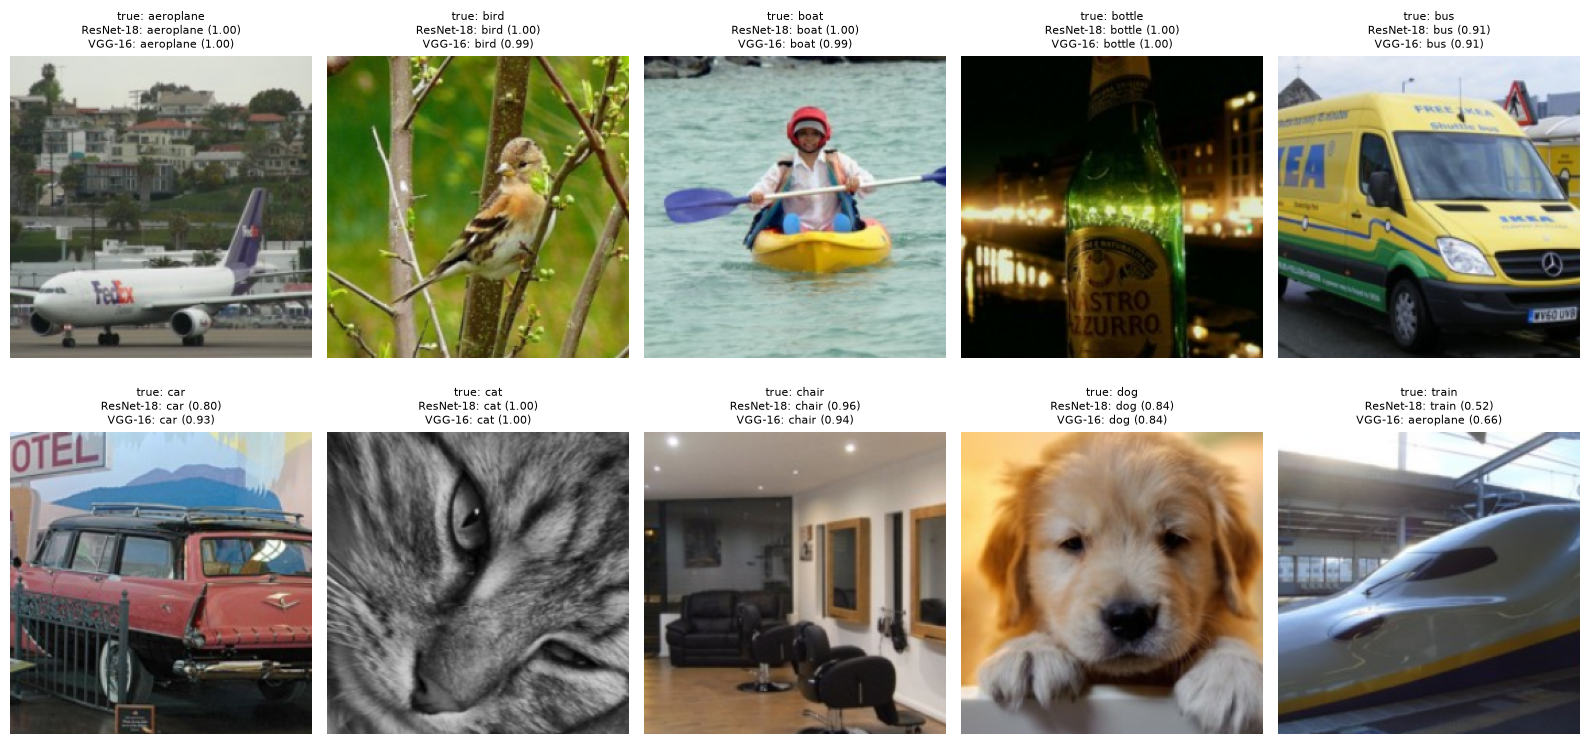

In [18]:
def pooled_head(linear: nn.Linear) -> nn.Linear:
    # A[s, i] = 1/|s| if ImageNet class i belongs to superclass s, else 0
    A = torch.zeros(len(PRETRAINED_SUPERCLASS_NAMES), linear.out_features, device=linear.weight.device)
    A[idx_to_super, torch.arange(linear.out_features, device=A.device)] = 1.0
    A /= A.sum(dim=1, keepdim=True)

    head = nn.Linear(linear.in_features, len(PRETRAINED_SUPERCLASS_NAMES), device=linear.weight.device)
    with torch.no_grad():
        head.weight.copy_(A @ linear.weight)
        head.bias.copy_(A @ linear.bias)
    return head


def make_pooled_model(model):
    model = copy.deepcopy(model)  # don't modify the original
    if hasattr(model, "fc"):      # ResNet: layer layer is .fc
        model.fc = pooled_head(model.fc)
    else:                         # VGG: last layer is end of .classifier
        model.classifier[-1] = pooled_head(model.classifier[-1])
    return model.eval()

pooled_models = {name: make_pooled_model(m) for name, m in pretrained_models.items()}

for name, m in pooled_models.items():
    head = m.fc if hasattr(m, "fc") else m.classifier[-1]
    print(f"{name:10s} head: {tuple(head.weight.shape)}")

show_superclass_predictions(pooled_models, sanity_images, sanity_labels)

In [19]:
for name, m in pooled_models.items():
    print_superclass_metrics(f"{name} (averaged head)", evaluate_superclass_model(m, val_loader))

ResNet-18 (averaged head)
  Loss:     0.2356
  Accuracy: 92.40%
    aeroplane   : 100.00%
    bird        : 100.00%
    boat        : 92.00%
    bottle      : 94.00%
    bus         : 96.00%
    car         : 84.00%
    cat         : 98.00%
    chair       : 88.00%
    dog         : 84.00%
    train       : 88.00%
VGG-16 (averaged head)
  Loss:     0.1951
  Accuracy: 93.40%
    aeroplane   : 100.00%
    bird        : 100.00%
    boat        : 94.00%
    bottle      : 96.00%
    bus         : 100.00%
    car         : 78.00%
    cat         : 100.00%
    chair       : 90.00%
    dog         : 86.00%
    train       : 90.00%


In [20]:
# Free the three full pretrained models before the training experiments below.
del prob_sum_models
del pooled_models
del pretrained_models

if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Part 4 — Network surgery

## 4.1 Reuse the same ImageNet → PASCAL mapping

For the trainable mini-ImageNet classifier, we now return to the actual **10-way task**. The auxiliary `others` label from Part 3 is intentionally dropped.

The same `PASCAL_TO_IMAGENET_IDS` mapping is reused to initialize a 10-way coarse classifier from the original 1000-way ImageNet head.


In [21]:
IMAGENET_CATEGORIES = ResNet18_Weights.DEFAULT.meta["categories"]
VGG_IMAGENET_CATEGORIES = VGG16_Weights.DEFAULT.meta["categories"]

# Both pretrained classifiers use the same ImageNet-1K class ordering.
assert IMAGENET_CATEGORIES == VGG_IMAGENET_CATEGORIES

HEAD_PASCAL_TO_IMAGENET_IDS = PASCAL_TO_IMAGENET_IDS

assert set(CLASSES) == set(HEAD_PASCAL_TO_IMAGENET_IDS)

for coarse_name, imagenet_ids in HEAD_PASCAL_TO_IMAGENET_IDS.items():
    assert len(imagenet_ids) == len(set(imagenet_ids)), (
        f"Duplicate ImageNet ID in {coarse_name}"
    )
    assert all(0 <= idx < 1000 for idx in imagenet_ids)

    print(f"\n{coarse_name}: {len(imagenet_ids)} ImageNet classes")
    for idx in imagenet_ids:
        print(f"  {idx:3d}: {IMAGENET_CATEGORIES[idx]}")



aeroplane: 2 ImageNet classes
  404: airliner
  895: warplane

bird: 59 ImageNet classes
    7: cock
    8: hen
    9: ostrich
   10: brambling
   11: goldfinch
   12: house finch
   13: junco
   14: indigo bunting
   15: robin
   16: bulbul
   17: jay
   18: magpie
   19: chickadee
   20: water ouzel
   21: kite
   22: bald eagle
   23: vulture
   24: great grey owl
   80: black grouse
   81: ptarmigan
   82: ruffed grouse
   83: prairie chicken
   84: peacock
   85: quail
   86: partridge
   87: African grey
   88: macaw
   89: sulphur-crested cockatoo
   90: lorikeet
   91: coucal
   92: bee eater
   93: hornbill
   94: hummingbird
   95: jacamar
   96: toucan
   97: drake
   98: red-breasted merganser
   99: goose
  100: black swan
  127: white stork
  128: black stork
  129: spoonbill
  130: flamingo
  131: little blue heron
  132: American egret
  133: bittern
  134: crane bird
  135: limpkin
  136: European gallinule
  137: American coot
  138: bustard
  139: ruddy turnstone
  

## 4.2 Construct the new 10-way output head

The original pretrained networks output 1000 ImageNet logits. We need 10 logits.

Compare three ways to initialize the replacement head.

### 4.2.1 Random initialization
Use the standard `nn.Linear` initialization.

### 4.2.2 Zero initialization

Set all weights and biases in the replacement classifier to zero.

### 4.2.3 Coarse-average initialization

For a coarse class \(c\),

$w_c=\frac{1}{|S_c|}\sum_{j\in S_c} w_j, \qquad b_c=\frac{1}{|S_c|}\sum_{j\in S_c} b_j,$

where \(S_c\) contains all ImageNet-1K fine classes mapped to the coarse category.

**Task:** implement all three initialization strategies in `build_coarse_head`.

- Hint 1: `nn.Linear()` already includes random initialization.
- Hint 2: Use `layer.weight` and `layer.bias` to access the parameters of an `nn.Linear` layer.
- Hint 3: For a PyTorch array `arr`, `arr.zero_()` replaces its values with zeros while `arr.copy_(new_arr)` replaces its values with the values of `new_arr`.


In [22]:
def make_linear_head(
    in_features,
    out_features,
    seed=HEAD_SEED,
):
    # note: `with` makes a dedicated RNG so the random head
    # is identical across comparisons for reproducibility.
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(seed)
        head = nn.Linear(in_features, out_features)
    return head


def build_coarse_head(
    pretrained_head,
    class_names,
    initialization,
):
    new_head = make_linear_head(
        pretrained_head.in_features,
        len(class_names),
    )

    if initialization == "random":
      # TODO Return the head with random initialization
      return new_head

    if initialization == "zero":
      with torch.no_grad():
        # TODO Return the head with zero initialization
        new_head.bias *= 0
        new_head.weight *= 0
      return new_head

    if initialization == "coarse_average":
      with torch.no_grad():
        # TODO Return the head with averaged parameters
        for coarse_id, coarse_name in enumerate(class_names):
            fine_ids = (HEAD_PASCAL_TO_IMAGENET_IDS[coarse_name])
            fine_weights = pretrained_head.weight[fine_ids]
            fine_biases = pretrained_head.bias[fine_ids]

            new_head.weight[coarse_id].copy_(fine_weights)
            new_head.bias[coarse_id].copy_(fine_biases)
      return new_head

    raise ValueError(
        f"Unknown initialization: {initialization}"
    )


### Short-answer question 2

**Question:** Why can zero initialization work for this one layer even though zero-initializing hidden layers is problematic?


**Answer**: TODO

**Question**: What if the output layer and the layer before it were _both_ initialized to zero? Can this optimize well?

**Answer**: TODO

## 4.3 Replace the original 1000-way classifier

In [ ]:
def build_model(
    architecture,
    backbone_init="pretrained",
    head_init="random",
):
    if architecture == "resnet18":
        if backbone_init == "pretrained":
            model = resnet18(weights=ResNet18_Weights.DEFAULT)
        elif backbone_init == "random":
            model = resnet18(weights=None)
        else:
            raise ValueError(f"Unknown backbone_init: {backbone_init}")
        model.fc = build_coarse_head(
            pretrained_head=model.fc,
            class_names=CLASSES,
            initialization=head_init,
        )
        return model

    if architecture == "vgg16":
        if backbone_init == "pretrained":
            model = vgg16(weights=VGG16_Weights.DEFAULT)
        elif backbone_init == "random":
            model = vgg16(weights=None)
        else:
            raise ValueError(f"Unknown backbone_init: {backbone_init}")
        model.classifier[-1] = build_coarse_head(
            pretrained_head=model.classifier[-1],
            class_names=CLASSES,
            initialization=head_init,
        )
        return model

    raise ValueError(f"Unknown architecture: {architecture}")


## 4.4 Evaluation helper

In [ ]:
@torch.no_grad()
def evaluate(model, loader, device):
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        logits = model(images)
        loss = F.cross_entropy(logits, labels)

        predictions = logits.argmax(dim=1)
        batch_size = labels.size(0)

        total_loss += loss.item() * batch_size
        total_correct += (predictions == labels).sum().item()
        total_examples += batch_size

    return {
        "loss": total_loss / total_examples,
        "accuracy": total_correct / total_examples,
    }

## 4.5 Sanity-check the three initializations before training

**Task:** evaluate the initial validation loss and accuracy of the `random`, `zero`, and `coarse_average` heads for both ResNet-18 and VGG-16. Report the results in a table with columns for the model, head, loss, and accuracy (with the formatting of your choosing).


In [ ]:
# TODO: Evaluate all three head initializations for both architectures
# before training, and store the results in `initialization_sanity_df`.
# Your code here.


### Short-answer question 3

**Question:** What should we expect from the zero-initialized head before optimization? Explain both the expected cross-entropy loss and top-1 accuracy on this balanced dataset.


# Part 5 — Experiment A: output head initialization

Keep the representation constant:

- Load the ImageNet-pretrained model,
- do not update the pre-trained parameters to "freeze" the representation, and
- optimize only the new 10-way head.

Compare:

1. random,
2. zero,
3. coarse-average.

This isolates the effect of **output head initialization**.

## 5.1 Freeze/unfreeze helpers

In [ ]:
def get_head(model, architecture):
    if architecture == "resnet18":
        return model.fc

    if architecture == "vgg16":
        return model.classifier[-1]

    raise ValueError(architecture)


def freeze_backbone(
    model,
    architecture,
):
    for parameter in model.parameters():
        parameter.requires_grad = False

    for parameter in get_head(
        model,
        architecture,
    ).parameters():
        parameter.requires_grad = True


def unfreeze_everything(model):
    for parameter in model.parameters():
        parameter.requires_grad = True


def set_training_mode(
    model,
    architecture,
    train_mode,
):
    if train_mode == "full":
        model.train()
        return

    if train_mode == "head_only":
        # Keep BatchNorm running statistics and VGG Dropout
        # fixed in the frozen representation.
        model.eval()

        # Linear head itself has no train/eval-dependent behavior,
        # but this expresses the intended mode.
        get_head(
            model,
            architecture,
        ).train()

        return

    raise ValueError(train_mode)

## 5.2 Training helper

In [124]:
def train_model(
    model,
    architecture,
    train_mode,
    train_loader,
    val_loader,
    optimizer,
    device,
    epochs,
):
    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": [],
    }

    if device.type == "cuda":
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats(device)
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    for epoch in range(epochs):
        set_training_mode(
            model,
            architecture,
            train_mode,
        )

        running_loss = 0.0
        running_correct = 0
        running_examples = 0

        progress = tqdm(
            train_loader,
            desc=f"Epoch {epoch + 1}/{epochs}",
        )

        for images, labels in progress:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            logits = model(images)
            loss = F.cross_entropy(logits, labels)

            loss.backward()
            optimizer.step()

            batch_size = labels.size(0)

            running_loss += loss.item() * batch_size
            running_correct += (
                logits.argmax(dim=1) == labels
            ).sum().item()
            running_examples += batch_size

            progress.set_postfix(
                loss=f"{running_loss / running_examples:.4f}",
                acc=f"{running_correct / running_examples:.2%}",
            )

        train_loss = running_loss / running_examples
        train_acc = running_correct / running_examples

        val_metrics = evaluate(
            model,
            val_loader,
            device,
        )

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_metrics["loss"])
        history["val_acc"].append(val_metrics["accuracy"])

        print(
            f"Epoch {epoch + 1:02d} | "
            f"train loss={train_loss:.4f} | "
            f"train acc={train_acc:.2%} | "
            f"val loss={val_metrics['loss']:.4f} | "
            f"val acc={val_metrics['accuracy']:.2%}"
        )

    if device.type == "cuda":
        torch.cuda.synchronize()

    total_time = time.perf_counter() - start_time

    if device.type == "cuda":
        peak_memory_gib = (
            torch.cuda.max_memory_allocated(device) / 1024**3
        )
    else:
        peak_memory_gib = float("nan")

    stats = {
        "training_time_seconds": total_time,
        "peak_gpu_memory_gib": peak_memory_gib,
    }

    return history, stats

## 5.3 Inference benchmark helper

In [125]:
def benchmark_inference(model, loader, device):
    # Measures model forward-pass time and peak allocated GPU memory.
    # DataLoader work and CPU -> GPU transfer are outside the timed region.
    model.eval()

    total_time = 0.0
    total_images = 0

    if device.type == "cuda":
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats(device)

    with torch.inference_mode():
        # Warm-up
        for batch_id, (images, _) in enumerate(loader):
            if batch_id >= 3:
                break

            images = images.to(device, non_blocking=True)
            _ = model(images)

        if device.type == "cuda":
            torch.cuda.synchronize()

        # Actual benchmark
        for images, _ in loader:
            images = images.to(device, non_blocking=True)

            if device.type == "cuda":
                torch.cuda.synchronize()

            start = time.perf_counter()
            _ = model(images)

            if device.type == "cuda":
                torch.cuda.synchronize()

            total_time += time.perf_counter() - start
            total_images += images.size(0)

    if device.type == "cuda":
        peak_memory_gib = (
            torch.cuda.max_memory_allocated(device) / 1024**3
        )
    else:
        peak_memory_gib = float("nan")

    return {
        "time_seconds": total_time,
        "images_per_second": total_images / total_time,
        "ms_per_image": total_time / total_images * 1000,
        "peak_gpu_memory_gib": peak_memory_gib,
    }

## 5.4 Generic experiment runner

In [126]:
EPOCHS = 5
LEARNING_RATE = 1e-4


def run_experiment(
    architecture,
    backbone_init,
    head_init,
    train_mode,
    experiment_name,
    epochs=EPOCHS,
    benchmark_after=False,
):
    print("\n" + "=" * 80)
    print(experiment_name)
    print(
        architecture,
        "| backbone:", backbone_init,
        "| head:", head_init,
        "| mode:", train_mode,
    )
    print("=" * 80)

    seed_everything(SEED)

    train_loader, val_loader = (
        make_loaders(SEED)
    )

    model = build_model(
        architecture=architecture,
        backbone_init=backbone_init,
        head_init=head_init,
    )

    if train_mode == "head_only":
        freeze_backbone(
            model,
            architecture,
        )

    elif train_mode == "full":
        unfreeze_everything(model)

    else:
        raise ValueError(train_mode)

    model = model.to(device)

    before = evaluate(
        model,
        val_loader,
        device,
    )

    print("\nBefore optimization:")
    print(
        f"  loss:     "
        f"{before['loss']:.4f}"
    )
    print(
        f"  accuracy: "
        f"{before['accuracy']:.2%}"
    )

    if head_init == "zero":
        print(
            "  expected zero-init CE:",
            f"{np.log(NUM_CLASSES):.4f}",
        )
        print(
            "  expected balanced chance accuracy:",
            f"{1 / NUM_CLASSES:.2%}",
        )

    trainable_parameters = [
        p
        for p in model.parameters()
        if p.requires_grad
    ]

    optimizer = torch.optim.Adam(
        trainable_parameters,
        lr=LEARNING_RATE,
    )

    history, stats = train_model(
        model=model,
        architecture=architecture,
        train_mode=train_mode,
        train_loader=train_loader,
        val_loader=val_loader,
        optimizer=optimizer,
        device=device,
        epochs=epochs,
    )

    final_metrics = evaluate(
        model,
        val_loader,
        device,
    )

    inference = None

    if benchmark_after:
        inference = benchmark_inference(
            model,
            val_loader,
            device,
        )

    print("\nFinal:")
    print(
        f"  val loss:     "
        f"{final_metrics['loss']:.4f}"
    )
    print(
        f"  val accuracy: "
        f"{final_metrics['accuracy']:.2%}"
    )
    print(
        f"  training time: "
        f"{stats['training_time_seconds']:.1f} s"
    )
    print(
        f"  peak GPU memory: "
        f"{stats['peak_gpu_memory_gib']:.2f} GiB"
    )

    result = {
        "history": history,
        "before": before,
        "final": final_metrics,
        "stats": stats,
        "inference": inference,
    }

    del optimizer
    del model

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result

## 5.5 Run Experiment A

**Task:** for both ResNet-18 and VGG-16, keep the pretrained backbone frozen and train only the replacement head. Compare the `random`, `zero`, and `coarse_average` initializations using the same training configuration.

Run all three conditions for both architectures with `run_experiment()` and store the results.


In [127]:
ARCHITECTURES = ["resnet18", "vgg16"]
HEAD_INITIALIZATIONS = ["random", "zero", "coarse_average"]

# TODO: Run Experiment A and store each result in `head_surgery_results`
# keyed by (arch, head) tuples.
head_surgery_results = {}


## 5.6 Plot Experiment A

**Task:** plot both training and validation loss/accuracy for the three initialization strategies. Use separate plots for each architecture.


In [128]:
# Run this cell and inspect the plots
colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]

for architecture in ARCHITECTURES:

    # Loss
    plt.figure(figsize=(8, 5))

    for i, head_init in enumerate(HEAD_INITIALIZATIONS):

        history = (
            head_surgery_results[
                (architecture, head_init)
            ]["history"]
        )

        epochs = range(
            1,
            len(history["train_loss"]) + 1,
        )

        color = colors[i]

        plt.plot(
            epochs,
            history["train_loss"],
            color=color,
            label=f"{head_init} train",
        )

        plt.plot(
            epochs,
            history["val_loss"],
            color=color,
            linestyle="--",
            label=f"{head_init} val",
        )

    plt.xlabel("Epoch")
    plt.ylabel("Cross-entropy loss")
    plt.title(
        f"{architecture}: "
        "output-head initialization"
    )
    plt.legend()
    plt.show()

    # Accuracy
    plt.figure(figsize=(8, 5))

    for i, head_init in enumerate(HEAD_INITIALIZATIONS):

        history = (
            head_surgery_results[
                (architecture, head_init)
            ]["history"]
        )

        epochs = range(
            1,
            len(history["train_acc"]) + 1,
        )

        color = colors[i]

        plt.plot(
            epochs,
            history["train_acc"],
            color=color,
            label=f"{head_init} train",
        )

        plt.plot(
            epochs,
            history["val_acc"],
            color=color,
            linestyle="--",
            label=f"{head_init} val",
        )

    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title(
        f"{architecture}: "
        "output-head initialization"
    )
    plt.legend()
    plt.show()

KeyError: ('resnet18', 'random')

<Figure size 800x500 with 0 Axes>

### Experiment A summary table

In [ ]:
rows = []

for (
    architecture,
    head_init,
), result in head_surgery_results.items():

    rows.append({
        "architecture": architecture,
        "head_init": head_init,
        "initial_loss":
            result["before"]["loss"],
        "initial_accuracy":
            result["before"]["accuracy"],
        "final_val_loss":
            result["final"]["loss"],
        "final_val_accuracy":
            result["final"]["accuracy"],
        "training_time_s":
            result["stats"][
                "training_time_seconds"
            ],
        "peak_gpu_memory_gib":
            result["stats"][
                "peak_gpu_memory_gib"
            ],
    })

head_surgery_df = pd.DataFrame(rows)
head_surgery_df

### Discussion Question

Compare the `random`, `zero`, and `coarse-average` initialization strategies.

1. Is zero initialization better or worse than random initialization? What could cause the difference? Will it always be this way for other data, models, and losses? Remember: neither have any information about the inputs or the pretrained parameters.
2. What additional information does the coarse-average initialization reuse from the pretrained ImageNet classifier?

**Answer:** TODO

# Part 6 — Experiment B: representation quality

Now let's learn only the output head from the **same seeded random initialization**.

Compare:

1. `random_frozen`
2. `pretrained_frozen`
3. `pretrained_full`

This isolates **representation quality and optimization** rather than head initialization.

## 6.1 Run Experiment B

**Task:** compare three representation conditions while keeping the output head at the same seeded random initialization:

1. random frozen backbone,
2. pretrained frozen backbone,
3. pretrained backbone with full fine-tuning.

Run all three conditions for both architectures with `run_experiment()` and store the results.


In [ ]:
# TODO: Define the three representation settings and run Experiment B.
# Store the outputs in `representation_results` as (arch, setting) tuples.
representation_results = {}


## 6.2 Plot Experiment B

**Task:** plot training and validation loss/accuracy for all three representation conditions, separately for each architecture.


In [ ]:
# Run this cell and inspect the plots
colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]

for architecture in ARCHITECTURES:

    # Loss
    plt.figure(figsize=(8, 5))

    for i, setting in enumerate(REPRESENTATION_EXPERIMENTS):

        history = (
            representation_results[
                (architecture, setting)
            ]["history"]
        )

        epochs = range(
            1,
            len(history["train_loss"]) + 1,
        )

        color = colors[i]

        plt.plot(
            epochs,
            history["train_loss"],
            color=color,
            label=f"{setting} train",
        )

        plt.plot(
            epochs,
            history["val_loss"],
            color=color,
            linestyle="--",
            label=f"{setting} val",
        )

    plt.xlabel("Epoch")
    plt.ylabel("Cross-entropy loss")
    plt.title(
        f"{architecture}: "
        "representation comparison"
    )
    plt.legend()
    plt.show()

    # Accuracy
    plt.figure(figsize=(8, 5))

    for i, setting in enumerate(REPRESENTATION_EXPERIMENTS):

        history = (
            representation_results[
                (architecture, setting)
            ]["history"]
        )

        epochs = range(
            1,
            len(history["train_acc"]) + 1,
        )

        color = colors[i]

        plt.plot(
            epochs,
            history["train_acc"],
            color=color,
            label=f"{setting} train",
        )

        plt.plot(
            epochs,
            history["val_acc"],
            color=color,
            linestyle="--",
            label=f"{setting} val",
        )

    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title(
        f"{architecture}: "
        "representation comparison"
    )
    plt.legend()
    plt.show()

### Experiment B summary table

In [ ]:
rows = []

for (
    architecture,
    setting,
), result in representation_results.items():

    row = {
        "architecture":
            architecture,

        "setting":
            setting,

        "initial_loss":
            result["before"]["loss"],

        "initial_accuracy":
            result["before"]["accuracy"],

        "final_val_loss":
            result["final"]["loss"],

        "final_val_accuracy":
            result["final"]["accuracy"],

        "training_time_s":
            result["stats"][
                "training_time_seconds"
            ],

        "peak_gpu_memory_gib":
            result["stats"][
                "peak_gpu_memory_gib"
            ],
    }

    inference = result["inference"]

    if inference is not None:

        row.update({
            "inference_time_s":
                inference["time_seconds"],

            "inference_images_per_s":
                inference[
                    "images_per_second"
                ],

            "inference_ms_per_image":
                inference[
                    "ms_per_image"
                ],

            "inference_peak_gpu_memory_gib":
                inference[
                    "peak_gpu_memory_gib"
                ],
        })

    rows.append(row)


representation_df = pd.DataFrame(rows)
representation_df

### Discussion Question

Compare the performance of `random_frozen`, `pretrained_frozen`, and `pretrained_full`. What do these three settings tell you about the value of ImageNet pretraining and the benefit of fine-tuning the pretrained representation? How does the amount of computation compare for these three and how do they rank from highest to lowest?

**Answer:** TODO

# Part 7 — From image classification to pixel classification

For our data, we now move to the mini-PASCAL VOC subset. The 10 foreground object categories are the same categories used above, but now that we are recognizing every pixel ("semantic segmentation") we require one additional class for the "background" or pixels that are not any of our 10 objects:

```text
10 object classes + 1 background class
```

This section therefore uses 11 output channels. The extra class is **background**, not the `others` bucket used in Part 3.

You will compare a frozen feature extractor with full fine-tuning and then study how the segmentation-head receptive field changes with kernel size and dilation.


For our model, we now move to a convolutional network that has no linear/fully-connected layers but only convolution layers, so we call it _fully convolutional_. Such a model takes an image as input and makes an image as output for spatial inference and learning.

For our metric, or measure of output quality, we now move to [Intersection-over-Union (IoU)](https://en.wikipedia.org/wiki/Jaccard_index) alongside the simple pixel accuracy. This is because the number of pixels per class is not balanced, and in particular there are a lot of background pixels, and we want our metric to measure the overall quality across classes and across the number of pixels.

## 7.1 Download the mini-PASCAL VOC subset

In [ ]:
!gdown 1GIzqAT5EVUKJXfkSCWQK4rPutHVPQMEX -O /content/voc_subset.zip
!unzip -q -o /content/voc_subset.zip -d /content/voc_subset

## 7.2 Segmentation preprocessing and labels

In [ ]:
from torchvision.datasets import VOCSegmentation
from torchvision import models
from IPython.display import clear_output

SEG_TRANSFORM = T.Compose([
    T.CenterCrop(224),
    T.ToTensor(),
    T.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD,
    ),
])

SEG_TARGET_TRANSFORM = T.Compose([
    T.CenterCrop(224),
    T.PILToTensor(),
])

SEG_CLASSES = ["background"] + CLASSES
assert len(SEG_CLASSES) == 11


def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    random.seed(worker_seed)
    np.random.seed(worker_seed)


def seed_segmentation(seed=1102):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True, warn_only=True)


seed_segmentation(1102)

def make_palette(num_classes):
    """
    Maps classes to colors in the style of PASCAL VOC.
    Close values are mapped to far colors for segmentation visualization.
    See http://host.robots.ox.ac.uk/pascal/VOC/voc2012/index.html#devkit

    Takes:
        num_classes: the number of classes
    Gives:
        palette: the colormap as a k x 3 array of RGB colors
    """
    palette = np.zeros((num_classes, 3), dtype=np.uint8)
    for k in range(0, num_classes):
        label = k
        i = 0
        while label:
            palette[k, 0] |= (((label >> 0) & 1) << (7 - i))
            palette[k, 1] |= (((label >> 1) & 1) << (7 - i))
            palette[k, 2] |= (((label >> 2) & 1) << (7 - i))
            label >>= 3
            i += 1
    return palette


def color_seg(seg, palette):
    """
    Replace classes with their colors.

    Takes:
        seg: H x W segmentation image of class IDs
    Gives:
        H x W x 3 image of class colors
    """
    return palette[seg.flat].reshape(seg.shape + (3,))

palette = make_palette(len(SEG_CLASSES))

def visualize_segmentation(image, mask):
    fig, axes = plt.subplots(1, 2, figsize=(8, 4))

    axes[0].imshow(
        denormalize(image).permute(1, 2, 0).numpy()
    )
    axes[0].set_title("Image")

    mask = mask.detach().cpu().numpy().squeeze()
    mask[mask == 255] = 0
    mask = color_seg(mask, palette)
    axes[1].imshow(
        mask,
        interpolation="nearest",
    )
    axes[1].set_title("Mask")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()


In [ ]:
# make segmentation datasets with their own transforms
# for the data (`transform`) and truth (`target_transform`)
seg_train_dataset = VOCSegmentation(
    "/content/voc_subset/voc10_train",
    image_set="train",
    transform=SEG_TRANSFORM,
    target_transform=SEG_TARGET_TRANSFORM,
)

seg_test_dataset = VOCSegmentation(
    "/content/voc_subset/voc10_test",
    image_set="val",
    transform=SEG_TRANSFORM,
    target_transform=SEG_TARGET_TRANSFORM,
)

# seed the example data loaders
generator = torch.Generator()
generator.manual_seed(SEED)

seg_train_loader = DataLoader(
    seg_train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
    drop_last=True,
    generator=generator,
)

seg_test_loader = DataLoader(
    seg_test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
    drop_last=False,
    generator=generator,
)

Let's inspect the shape of the input images and true segmentations or "masks" and visualize a pair.

In [ ]:
seg_images, seg_masks = next(iter(seg_train_loader))
print("Segmentation image batch:", seg_images.shape)
print("Segmentation mask batch:", seg_masks.shape)

seg_example_idx = 0
visualize_segmentation(seg_images[seg_example_idx], seg_masks[seg_example_idx])

## 7.3 Fully Convolutional Architecture, Evaluation, and Training

We will build the segmentation model in three steps:

```
input image → convolutional features → convolutional segmentation head → output image
```

**Task 1: Extract and collect convolutional features**

We provide `build_seg_extractor()` to collect the right layers from ResNet-18 and VGG-16 then return the architecture and number of output channels.
For ResNet-18, we remove the average pooling and final classification layer.
For VGG-16, we take the layers in model.features before the fully-connected layers.

Your task is to run the ResNet-18 feature extractor and check the dimensions of the output.

In [ ]:
def build_seg_extractor(backbone="resnet18"):
    if backbone == "resnet18":
        model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        feature_extractor = nn.Sequential(*list(model.children())[:-2])
        feature_dim = 512
    elif backbone == "resnet50":
        model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        feature_extractor = nn.Sequential(*list(model.children())[:-2])
        feature_dim = 2048
    elif backbone == "vgg16":
        model = models.vgg16(weights=models.VGG16_Weights.DEFAULT)
        feature_extractor = model.features
        feature_dim = 512
    else:
        raise ValueError("backbone must be 'resnet18', 'resnet50' or 'vgg16'")

    return feature_extractor, feature_dim

In [ ]:
# TODO: make a ResNet-18 feature extractor, run it on the `seg_images` example input, and print the dimensions
# seg_extractor, output_channels = ...
# seg_features = seg_extractor(seg_images)
# print("Feature shape: ", seg_features.size())
# print("Truth shape: ", seg_masks.size())

**Question**: What size is the output w.r.t. the input? What needs to change for the shape of the output to be compatible with the shape of the truth for the channel dimension and spatial dimensions?

**Answer**: TODO

**Task 2: Add the segmentation head to make predictions**

We provide `build_seg_head` to make a convolutional predictor from features to classes.

Your task is to instantiate a 3x3 convolutional predictor for the right number of classes that keeps the output spatial size the same as the input spatial size. Hint: use `kernel_size`, `padding`, and `stride`.

In [ ]:
def build_seg_head(feature_dim, num_classes, kernel_size=1, dilation=1, padding=0, stride=1):
  seg_head = nn.Conv2d(feature_dim, num_classes, kernel_size=kernel_size, stride=stride, padding=padding, dilation=dilation)
  return seg_head

In [ ]:
# TODO: make the convolutional segmentation head for a 3x3 filter with the same-size spatial dimensions
# seg_head = build_seg_head(...)
# seg_outputs = seg_head(seg_features)
# print("Output shape: ", seg_outputs.shape)

**Task 3: Interpolate predictions to the full spatial dimensions**

Our output shape is still too small: we need an output for every pixel.
To do this efficiently we will simply _interpolate_ (or "upsample") the predictions.
There is more than one way to do this.

Your task is to compare interpolation with "nearest" and "bilinear" modes.

To make this more interesting, we are first going to take our coarse classification head and turn it into a segmentation head, so we can look at its predictions when run fully convolutionally.

**Question**: How can we reuse the parameters of the last FC layer in the classifier for the 1x1 convolution layer in our segmentation head? Hint: What are the parameter shapes?

**Answer**: TODO

In [ ]:
# make classification head and collect its parameters
class_model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
class_head = build_coarse_head(
    class_model.fc,
    SEG_CLASSES[1:],
    initialization="coarse_average",
)
class_weight = class_head.weight

# make segmentation head and replace its parameters by net surgery:
# - for the background class use zero init
# - for the object classes use the coarse init
seg_head = build_seg_head(feature_dim, len(SEG_CLASSES), kernel_size=1, padding=0, stride=1)
with torch.no_grad():
  seg_head.weight.zero_()
  seg_head.weight[1:].copy_(class_weight.reshape(seg_head.weight[1:].size()))

# make prediction with new coarse head
seg_outputs = seg_head(seg_features)

del class_model, class_head

In [ ]:
h, w = seg_images.shape[-2:]

seg_outputs_nearest = F.interpolate(seg_outputs, size=(h, w), mode='nearest')
seg_outputs_bilinear = F.interpolate(seg_outputs, size=(h, w), mode='bilinear', align_corners=False)

print("Nearest Shape: ", seg_outputs_nearest.size())
print("Bilinear Shape: ", seg_outputs_bilinear.size())

seg_nearest = seg_outputs_nearest.detach().cpu().numpy()[seg_example_idx].argmax(0)
seg_bilinear = seg_outputs_bilinear.detach().cpu().numpy()[seg_example_idx].argmax(0)

visualize_segmentation(seg_images[seg_example_idx], seg_masks[seg_example_idx])

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].set_title("Nearest")
axes[0].imshow(
    color_seg(seg_nearest, palette),
    interpolation="nearest",
)
axes[0].set_axis_off()

axes[1].set_title("Bilinear")
axes[1].imshow(
    color_seg(seg_bilinear, palette),
    interpolation="nearest",
)
axes[1].set_axis_off()
plt.tight_layout()

del seg_outputs_nearest, seg_outputs_bilinear, seg_nearest, seg_bilinear

**Question**: Are there any correct pixels in this prediction? How would you describe nearest vs. bilinear? Which looks more
spatially precise to you, even for this predictor that has not been trained for segmentation yet?

**Answer**: TODO

In [ ]:
# Clean up
del seg_images, seg_masks, seg_features, seg_outputs, seg_extractor, seg_head

Now we provide helpers for the segmentation architecture, evaluation, and training that put together what we have just done for our experiments.

In [ ]:
class SegmentationModel(nn.Module):
    def __init__(self, backbone="resnet18", num_classes=11, freeze_backbone=False, kernel_size=1, dilation=1, padding=0, stride=1):
        super().__init__()

        self.feature_extractor, feature_dim = build_seg_extractor(backbone)

        self.head = build_seg_head(feature_dim, num_classes, kernel_size=kernel_size, stride=stride, padding=padding, dilation=dilation)
        self.freeze_backbone = freeze_backbone

        if freeze_backbone:
            self.feature_extractor.requires_grad_(False)
            self.feature_extractor.eval()

    def train(self, mode=True):
        super().train(mode)
        if self.freeze_backbone:
            self.feature_extractor.eval()
        return self

    def forward(self, images):
        features = self.feature_extractor(images)
        logits = self.head(features)
        return F.interpolate(
            logits, size=images.shape[-2:],
            mode="bilinear", align_corners=False
        )

@torch.no_grad()
def evaluate_segmentation(model, dataloader, device, num_classes=11):
    was_training = model.training
    model.eval()

    confusion = torch.zeros(
        num_classes, num_classes, dtype=torch.int64, device=device
    )
    total_loss, total_pixels = 0.0, 0

    try:
        for images, masks in dataloader:
            images = images.to(device)
            masks = masks.squeeze(1).long().to(device)
            valid = masks != 255

            logits = model(images)
            pixel_loss = F.cross_entropy(
                logits, masks, ignore_index=255, reduction="none"
            )
            total_loss += pixel_loss.sum().item()
            total_pixels += valid.sum().item()

            predictions = logits.argmax(1)
            confusion += torch.bincount(
                num_classes * masks[valid] + predictions[valid],
                minlength=num_classes**2,
            ).reshape(num_classes, num_classes)
    finally:
        model.train(was_training)

    confusion = confusion.float()
    intersection = confusion.diag()
    union = confusion.sum(0) + confusion.sum(1) - intersection
    present = union > 0
    iou = intersection / union.clamp_min(1)

    return {
        "loss": total_loss / total_pixels if total_pixels else float("nan"),
        "mIoU": iou[present].mean().item(),
        "pixel_accuracy": (
            intersection.sum().item() / total_pixels
            if total_pixels else float("nan")
        ),
        "per_class_IoU": iou.masked_fill(
            ~present, float("nan")
        ).cpu().tolist(),
    }


def print_segmentation_results(metrics, message=None, class_names=None, per_class_iou=True):
    if message:
        print(message)

    print(f"Loss: {metrics['loss']:.4f}")
    print(f"mIoU: {metrics['mIoU']:.2%}")
    print(f"Pixel accuracy: {metrics['pixel_accuracy']:.2%}")

    if per_class_iou:
        names = SEG_CLASSES if class_names is None else class_names
        for name, iou in zip(names, metrics["per_class_IoU"]):
            print(f"  {name:12s}: {iou:.2%}")


def fine_tune_segmentation(
    model, train_loader, train_eval_loader, test_loader,
    optimizer, device, epochs=5, evaluate_train=False,
):
    history = []

    for epoch in range(1, epochs + 1):
        model.train()
        total_loss, total_pixels = 0.0, 0

        with tqdm(train_loader, desc=f"Epoch {epoch}/{epochs}") as progress:
            for images, masks in progress:
                images = images.to(device)
                masks = masks.squeeze(1).long().to(device)
                valid_pixels = (masks != 255).sum()

                if valid_pixels.item() == 0:
                    continue

                optimizer.zero_grad(set_to_none=True)
                logits = model(images)
                pixel_loss = F.cross_entropy(
                    logits, masks, ignore_index=255, reduction="none"
                )
                loss = pixel_loss.sum() / valid_pixels
                loss.backward()
                optimizer.step()

                total_loss += pixel_loss.detach().sum().item()
                total_pixels += valid_pixels.item()
                progress.set_postfix(loss=f"{total_loss / total_pixels:.4f}")

        train_metrics = {
            "loss": total_loss / total_pixels if total_pixels else float("nan")
        }
        if evaluate_train:
            train_metrics = evaluate_segmentation(model, train_eval_loader, device)

        test_metrics = evaluate_segmentation(model, test_loader, device)
        history.append({
            "epoch": epoch,
            "train": train_metrics,
            "test": test_metrics,
        })

        message = f"Train loss={train_metrics['loss']:.4f}"
        if evaluate_train:
            message += f", mIoU={train_metrics['mIoU']:.2%}"
        print(
            f"{message} | Test loss={test_metrics['loss']:.4f}, "
            f"mIoU={test_metrics['mIoU']:.2%}"
        )

    return history


def run_segmentation_experiment(
    seed, epochs=5, lr=1e-4, device="cuda", model=None,
    batch_size=16, num_workers=2, evaluate_train=False, **model_parameters,
):
    if epochs < 1:
        raise ValueError("epochs must be at least 1")

    seed_segmentation(seed)

    def make_loader(dataset, shuffle, loader_seed):
        return DataLoader(
            dataset,
            batch_size=batch_size,
            shuffle=shuffle,
            drop_last=False,
            num_workers=num_workers,
            pin_memory=torch.device(device).type == "cuda",
            generator=torch.Generator().manual_seed(loader_seed),
            worker_init_fn=seed_worker,
        )

    train_loader = make_loader(seg_train_dataset, True, seed)
    train_eval_loader = make_loader(seg_train_dataset, False, seed + 1)
    test_loader = make_loader(seg_test_dataset, False, seed + 2)

    if model is None:
        model = SegmentationModel(num_classes=11, **model_parameters)
    model = model.to(device)

    optimizer = torch.optim.Adam(
        (p for p in model.parameters() if p.requires_grad),
        lr=lr,
    )

    history = fine_tune_segmentation(
        model, train_loader, train_eval_loader, test_loader,
        optimizer, device, epochs, evaluate_train
    )
    return model, history


def run_segmentation_multiple_times(
    seeds, epochs=5, lr=1e-4, device="cuda", evaluate_train=False, **model_parameters,
):
    seeds = list(seeds)
    if not seeds:
        raise ValueError("Provide at least one seed")

    runs, histories = [], []

    for seed in seeds:
        clear_output(wait=True)
        print(f"Running seed {seed}")

        model, history = run_segmentation_experiment(
            seed, epochs=epochs, lr=lr,
            device=device, evaluate_train=evaluate_train, **model_parameters,
        )
        runs.append(history[-1]["test"])
        histories.append(history)

        del model

    metrics = {
        "seeds": seeds,
        "results": runs,
        "histories": histories,
    }

    for key in runs[0]:
        values = np.asarray([run[key] for run in runs], dtype=float)
        count = np.sum(~np.isnan(values), axis=0)
        mean = np.full(values.shape[1:], np.nan)
        np.divide(np.nansum(values, axis=0), count, out=mean, where=count > 0)

        variance = np.full_like(mean, np.nan)
        np.divide(
            np.nansum((values - mean) ** 2, axis=0),
            count - 1,
            out=variance,
            where=count > 1,
        )
        metrics[key] = {
            "mean": mean.tolist(),
            "std": np.sqrt(variance).tolist(),
            "variance": variance.tolist(),
        }

    for seed, result in zip(seeds, runs):
        print(f"Seed {seed}: test mIoU={result['mIoU']:.2%}")

    print(
        f"Mean test mIoU: {metrics['mIoU']['mean']:.2%} "
        f"± {100 * metrics['mIoU']['std']:.2f} percentage points"
    )
    return metrics

def plot_history(history):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    for split in ("train", "test"):
        for ax, key, scale in (
            (axes[0], "loss", 1),
            (axes[1], "mIoU", 100),
        ):
            points = [
                (row["epoch"], row[split][key] * scale)
                for row in history if key in row[split]
            ]
            if points:
                epochs, values = zip(*points)
                ax.plot(epochs, values, label=split)

    axes[0].set(title="Loss", xlabel="Epoch", ylabel="Cross-entropy")
    axes[1].set(title="mIoU", xlabel="Epoch", ylabel="mIoU (%)")

    for ax in axes:
        ax.legend()
        ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

## 7.4 Frozen ResNet-18 feature extractor

**Task:** train only a new 1×1 convolution segmentation head on top of a frozen ImageNet-pretrained ResNet-18 backbone. Report the final test loss, mIoU, and pixel accuracy.


In [ ]:
# Run the frozen ResNet-18 segmentation experiment.
model_res18, history_res18_head_only = run_segmentation_experiment(seed=1102, epochs=EPOCHS, lr=1e-4, device=device, backbone="resnet18", freeze_backbone=True)
plot_history(history_res18_head_only)

## 7.5 Fully fine-tuned VGG-16

**Task:** fine-tune the full ImageNet-pretrained VGG-16 segmentation model. Compare its performance and training cost with the frozen ResNet-18 experiment.


In [ ]:
# TODO: Run the fully fine-tuned VGG-16 segmentation experiment based on the ResNet-18 segmentation experiment above.
# Your code here.


### 7.6 Fully fine-tuned ResNet-18 across seeds

**Task:** Run the fully fine-tuned ResNet-18 segmentation model across the provided random seeds. Inspect the mean and standard deviation of the final mIoU.


In [ ]:
seeds = [1234, 5678, 9101]
metrics_res18_full = run_segmentation_multiple_times(seeds=seeds, epochs=EPOCHS, lr=1e-4, device=device, backbone="resnet18", freeze_backbone=False)

**Question**: Are the results sensitive the seed? How could we be more certain about the result?

**Answer**: TODO

## 7.7 ResNet-18 with a 3×3 segmentation head

**Task:** replace the 1×1 segmentation head with a 3×3 head while preserving spatial resolution (= while keeping the output spatial dimensions equal to the input spatial dimensions for the layer). Run the same multi-seed evaluation and compare the result with the 1×1 head.


In [ ]:
# TODO: Run the 3×3-head ResNet-18 experiment across `seeds` based on the experiment above.
# Your code here.


## 7.8 ResNet-18 with a dilated 3×3 segmentation head

**Task:** use a 3×3 head with dilation 2 ([paper](https://arxiv.org/abs/1511.07122) | [PyTorch documentation](https://docs.pytorch.org/docs/2.14/generated/torch.nn.Conv2d.html)). As before, keep the spatial dimensions unchanged so that the input height and width equal the output height and width. Compare its context window / receptive field and segmentation performance with the previous heads.

**Question**: What is the effective size the dilated filters? That is, what would be the equivalent `kernel_size` to achieve the same size without dilation?

**Answer**: TODO.


In [ ]:
# TODO: Run the dilated 3×3-head ResNet-18 experiment across `seeds`.
# Your code here.


## 7.9 Cumulative head training and fine-tuning

Instead of training each head from scratch, progressively expand the trained head to increase its context window:

```text
1×1 → 3×3 → dilated 3×3
```

When expanding a 1×1 head to 3×3, copy the learned 1×1 weights into the center of the new kernel and initialize the off-center weights to zero.

**Task:** implement `expand_head`, then compare cumulative fine-tuning against training the 1×1-head control for the same total number of epochs. Hint: Given an existing head `old_conv`, make a new head `new_conv = nn.Conv2d(old_conv.in_channels, old_conv.out_channels, ...)` then set its parameters. See the hints for `build_coarse_head()` as a reminder of how to alter layer parameters.

In [ ]:
def expand_head(old, dilation=1):
    new = nn.Conv2d(
        old.in_channels,
        old.out_channels,
        kernel_size=3,
        padding=dilation,
        dilation=dilation,
        bias=old.bias is not None,
    ).to(device=old.weight.device, dtype=old.weight.dtype)

    with torch.no_grad():
        # TODO: Initialize the 3×3 convolution parameters from `old`
        # where `old` can be a 1x1 convolution or 3x3 convolution
        raise NotImplementedError
    return new

In [ ]:
# TODO: Run the 1×1 → 3×3 → dilated 3×3 cumulative experiments,
# by calling `run_segmentation_experiment()` and `expand_head()`,
# and run each stage for 5 epochs.
# Your code here.


In [ ]:
# TODO: Train the 1×1-head control experiment for the same total number of epochs.
# Your code here.


In [ ]:
# Print and compare the final cumulative and control metrics.
print_segmentation_results(metric_expansion_r3[-1]["test"], "cumulative fine-tuning")
print_segmentation_results(metric_controlled[-1]["test"], "standard fine-tuning")


**Question**: Which turned out better, cumulative fine-tuning or standard fine-tuning? Which was simpler to implement? How do you think longer fine-tuning of the final cumulative architecture (3x3 with dilation 2) would compare?

**Answer**: TODO

# Part 8 — Scaling up to ResNet-50

In this notebook we have extensively worked with ResNet18 and VGG16. Since model complexity grows with number of parameters and number of layers, let's see what happens if we simply scale up the model size by using a ResNet-50.

ResNet50 has 50 layers, and around 25M parameters.

## Classification: Full Finetuning with ResNet-50

In [ ]:
resnet50_ci = resnet50(weights=ResNet50_Weights.DEFAULT)
resnet50_ci.fc = build_coarse_head(
    resnet50_ci.fc,
    CLASSES,
    initialization="coarse_average",
)
resnet50_ci = resnet50_ci.to(device)
unfreeze_everything(resnet50_ci)
optimizer = torch.optim.Adam(
        resnet50_ci.parameters(),
        lr=LEARNING_RATE,
    )
train_loader, val_loader = (make_loaders(SEED))

def train_classification(
    model,
    train_loader,
    val_loader,
    optimizer,
    device,
    epochs,
):
    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": [],
    }

    if device.type == "cuda":
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats(device)
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    for epoch in range(epochs):
        model.train()

        running_loss = 0.0
        running_correct = 0
        running_examples = 0

        progress = tqdm(
            train_loader,
            desc=f"Epoch {epoch + 1}/{epochs}",
        )

        for images, labels in progress:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            logits = model(images)
            loss = F.cross_entropy(logits, labels)

            loss.backward()
            optimizer.step()

            batch_size = labels.size(0)

            running_loss += loss.item() * batch_size
            running_correct += (
                logits.argmax(dim=1) == labels
            ).sum().item()
            running_examples += batch_size

            progress.set_postfix(
                loss=f"{running_loss / running_examples:.4f}",
                acc=f"{running_correct / running_examples:.2%}",
            )

        train_loss = running_loss / running_examples
        train_acc = running_correct / running_examples

        val_metrics = evaluate(
            model,
            val_loader,
            device,
        )

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_metrics["loss"])
        history["val_acc"].append(val_metrics["accuracy"])

        print(
            f"Epoch {epoch + 1:02d} | "
            f"train loss={train_loss:.4f} | "
            f"train acc={train_acc:.2%} | "
            f"val loss={val_metrics['loss']:.4f} | "
            f"val acc={val_metrics['accuracy']:.2%}"
        )

    if device.type == "cuda":
        torch.cuda.synchronize()

    total_time = time.perf_counter() - start_time

    if device.type == "cuda":
        peak_memory_gib = (
            torch.cuda.max_memory_allocated(device) / 1024**3
        )
    else:
        peak_memory_gib = float("nan")

    stats = {
        "training_time_seconds": total_time,
        "peak_gpu_memory_gib": peak_memory_gib,
    }

    return history, stats

resnet50_hist, resnet50_stats = train_classification(resnet50_ci, train_loader, val_loader, optimizer, device, EPOCHS)

In [ ]:
print("Classification Comparison (models from part 6 vs. ResNet50)")
pf = "pretrained_full"
classification_comparison = [
    {
        "model": "ResNet-18 (fully fine-tuned)",
        "final_val_loss": representation_results[("resnet18",pf)]["final"]["loss"],
        "final_val_accuracy": representation_results[("resnet18",pf)]["final"]["accuracy"],
        "training_time_s": representation_results[("resnet18",pf)]["stats"]["training_time_seconds"],
        "peak_gpu_memory_gib": representation_results[("resnet18",pf)]["stats"]["peak_gpu_memory_gib"],
    },
    {
        "model": "VGG-16 (fully fine-tuned)",
        "final_val_loss": representation_results[("vgg16",pf)]["final"]["loss"],
        "final_val_accuracy": representation_results[("vgg16",pf)]["final"]["accuracy"],
        "training_time_s": representation_results[("vgg16",pf)]["stats"]["training_time_seconds"],
        "peak_gpu_memory_gib": representation_results[("vgg16",pf)]["stats"]["peak_gpu_memory_gib"],
    },
    {
        "model": "ResNet-50 (fully fine-tuned)",
        "final_val_loss": resnet50_hist["val_loss"][-1],
        "final_val_accuracy": resnet50_hist["val_acc"][-1],
        "training_time_s": resnet50_stats["training_time_seconds"],
        "peak_gpu_memory_gib": resnet50_stats["peak_gpu_memory_gib"],
    },
]

pd.DataFrame(classification_comparison)

## Segmentation: Full Finetuning with ResNet50

In [ ]:
model_resnet50_full, history_resnet50_full = run_segmentation_experiment(seed=1102, epochs=EPOCHS, lr=1e-4, device=device, backbone="resnet50", freeze_backbone=False)
plot_history(history_resnet50_full)

# Part 9. Final discussion

Reflect on the results across the notebook to connect the progression from image classification to pixel classification. Please discuss these points in 1-3 sentences each.

1. Why is it useful to test the untouched ImageNet models before changing their classifier heads?
2. What do the frozen-backbone experiments tell you about the quality of pretrained features?
3. When does full fine-tuning provide enough improvement to justify its  computation?
4. How do kernel size and dilation change the receptive field of the segmentation head?
5. Did the cumulative head-expansion experiment help? Give a hypothesis for the result you observed.


**Answer:** TODO